# Analisi Diffusione COVID-19

**Autore:** Francesco Autorino

**Esame finale - W12D4**

In questo notebook analizzo il dataset COVID-19 raccolto e curato da *Our World in Data*, disponibile su GitHub all'indirizzo:
[https://github.com/owid/covid-19-data/tree/master/public/data](https://github.com/owid/covid-19-data/tree/master/public/data)

I dati vengono scaricati direttamente dal file CSV:
`https://raw.githubusercontent.com/owid/covid-19-data/refs/heads/master/public/data/owid-covid-data.csv`

**Indice**
0. [Import delle librerie e caricamento del dataset](#0)
1. [Dimensioni del dataset e metadati](#1)
    - 1.1 Controllo e rimozione dei duplicati
    - 1.2 Consultazione del codebook ufficiale OWID
2. [Numero di casi per continente e percentuale sul totale mondiale](#2)
3. [Analisi Italia 2022](#3)
    - 3.1bis Verifica della cadenza settimanale
4. [Confronto pazienti in terapia intensiva: Italia, Germania, Francia](#4)
    - 4.1bis Localizzazione temporale dei dati mancanti in ICU
5. [Pazienti ospedalizzati nel 2021: Italia, Germania, Francia, Spagna](#5)
6. [Mini-extra: tasso di letalita' (Case-Fatality Ratio)](#6)
7. [Conclusioni](#7)

## 0. Import delle librerie e caricamento del dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)


# --- Formattatori per gli assi: etichette leggibili al posto della notazione 1eN ---
def _fmt_grandezze(x, _pos=None):
    """Etichette compatte: 'mila'/'Mln' con virgola decimale (stile IT)."""
    a = abs(x)
    if a >= 1_000_000:
        s = f"{x/1_000_000:.1f}".rstrip('0').rstrip('.').replace('.', ',')
        return f"{s} Mln"
    if a >= 1_000:
        return f"{x/1_000:.0f} mila"
    return f"{x:.0f}"

def _fmt_interi(x, _pos=None):
    """Interi con separatore delle migliaia stile italiano (punto)."""
    return f"{x:,.0f}".replace(',', '.')

def _fmt_percento(x, _pos=None):
    return f"{x:.1f}%".replace('.', ',')

FMT_GRANDEZZE = FuncFormatter(_fmt_grandezze)   # casi, ricoveri (mila / Mln)
FMT_INTERI = FuncFormatter(_fmt_interi)         # pazienti ICU (interi)
FMT_PERCENTO = FuncFormatter(_fmt_percento)     # CFR (%)

# Carichiamo il dataset direttamente dall'URL raw di GitHub
url = "https://raw.githubusercontent.com/owid/covid-19-data/refs/heads/master/public/data/owid-covid-data.csv"
df = pd.read_csv(url, low_memory=False)
df['date'] = pd.to_datetime(df['date'])

df.head()

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN


In [2]:
# La palette per nazione la definisco qui perche' la riuso in tutti i grafici che
# confrontano Italia/Germania/Francia/Spagna: cosi' lo stesso Paese ha sempre lo
# stesso colore in ogni sezione (piu' facile confrontare i grafici a colpo d'occhio).
PALETTE_NAZIONI = {
    'Italy': '#1f77b4',    # blu
    'Germany': '#d62728',  # rosso
    'France': '#2ca02c',   # verde
    'Spain': '#ff7f0e',    # arancione
}

## 1. Dimensioni del dataset e metadati

Si richiede di verificare le dimensioni del dataset e i relativi metadati.

In [3]:
print(f"Numero di righe: {df.shape[0]}")
print(f"Numero di colonne: {df.shape[1]}")
print()
df.info()

Numero di righe: 429435
Numero di colonne: 67

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 429435 entries, 0 to 429434
Data columns (total 67 columns):
 #   Column                                      Non-Null Count   Dtype         
---  ------                                      --------------   -----         
 0   iso_code                                    429435 non-null  object        
 1   continent                                   402910 non-null  object        
 2   location                                    429435 non-null  object        
 3   date                                        429435 non-null  datetime64[ns]
 4   total_cases                                 411804 non-null  float64       
 5   new_cases                                   410159 non-null  float64       
 6   new_cases_smoothed                          408929 non-null  float64       
 7   total_deaths                                411804 non-null  float64       
 8   new_deaths                 

In [4]:
# Percentuale di valori mancanti per colonna (le prime 15 colonne con più NaN)
(df.isna().mean() * 100).sort_values(ascending=False).head(15).round(2)

weekly_icu_admissions_per_million          97.44
weekly_icu_admissions                      97.44
excess_mortality_cumulative_per_million    96.88
excess_mortality                           96.88
excess_mortality_cumulative                96.88
excess_mortality_cumulative_absolute       96.88
weekly_hosp_admissions_per_million         94.30
weekly_hosp_admissions                     94.30
icu_patients                               90.89
icu_patients_per_million                   90.89
hosp_patients_per_million                  90.53
hosp_patients                              90.53
total_boosters_per_hundred                 87.52
total_boosters                             87.52
new_vaccinations                           83.47
dtype: float64

### 1.1 Controllo e rimozione dei duplicati

Trattandosi di un dataset longitudinale (un valore per ogni combinazione Paese/data), il controllo più significativo non è sul duplicato dell'intera riga, ma sulla **chiave naturale `(location, date)`**: se esistesse più di una riga per la stessa nazione nello stesso giorno, qualunque aggregazione successiva (somme, medie, grafici temporali) risulterebbe falsata. Verifichiamo, individuiamo *dove* cadono gli eventuali duplicati e li rimuoviamo prima di procedere.

In [5]:
duplicati_riga_intera = df.duplicated().sum()
duplicati_chiave = df.duplicated(subset=['location', 'date']).sum()

print(f"Righe duplicate (tutte le colonne identiche): {duplicati_riga_intera}")
print(f"Righe duplicate sulla chiave (location, date): {duplicati_chiave}")

# Individuiamo su quali 'location' cadono i duplicati (per capirne la natura)
loc_duplicate = sorted(
    df.loc[df.duplicated(subset=['location', 'date'], keep=False), 'location'].unique()
)
print("\nLocation coinvolte nei duplicati:")
print(loc_duplicate)

Righe duplicate (tutte le colonne identiche): 0
Righe duplicate sulla chiave (location, date): 7770

Location coinvolte nei duplicati:
['East Timor', 'European Union (27)', 'Faroe Islands', 'High-income countries', 'Low-income countries', 'Lower-middle-income countries', 'Upper-middle-income countries']


I duplicati **esistono** (righe duplicate sulla chiave `(location, date)`) e cadono su un insieme circoscritto di *location*: alcuni territori (`East Timor`, `Faroe Islands`) e alcuni aggregati (`European Union (27)`, i gruppi di reddito). Ispezionando le coppie, per ogni chiave duplicata una riga è popolata e l'altra riporta valori nulli sulle serie temporali. **Nessuno** dei sei continenti, della riga `World` o dei Paesi che analizzeremo (Italia, Germania, Francia, Spagna) è tra questi: le analisi successive non ne sarebbero comunque state falsate. Per pulizia procediamo comunque a rimuoverli, tenendo per ogni chiave la riga con più valori non nulli.

In [6]:
# Rimuoviamo i duplicati sulla chiave (location, date) tenendo, per ogni coppia,
# la riga con più valori non nulli (quella effettivamente popolata).
righe_prima = len(df)
df['_n_non_null'] = df.notna().sum(axis=1)
df = (
    df.sort_values('_n_non_null', ascending=False)
      .drop_duplicates(subset=['location', 'date'], keep='first')
      .drop(columns='_n_non_null')
      .sort_values(['location', 'date'])
      .reset_index(drop=True)
)

print(f"Righe prima della pulizia: {righe_prima:,}")
print(f"Righe dopo la rimozione dei duplicati: {len(df):,}")
print(f"Duplicati residui sulla chiave (location, date): {df.duplicated(subset=['location', 'date']).sum()}")

Righe prima della pulizia: 429,435
Righe dopo la rimozione dei duplicati: 421,665
Duplicati residui sulla chiave (location, date): 0


Dopo la rimozione, ogni combinazione `(location, date)` è rappresentata da un'unica osservazione: possiamo procedere con le analisi.

**Nota sui metadati (dalla pagina GitHub del dataset):**
- Il file `owid-covid-data.csv` è aggiornato periodicamente e contiene dati su casi, decessi, vaccinazioni, test, ricoveri, terapie intensive e indicatori socio-economici, per ~250 tra paesi e aggregati (continenti, gruppi di reddito, Unione Europea, "World").
- La colonna `continent` è **nulla** per le righe che rappresentano aggregati (continenti stessi, gruppi di reddito, "World"), mentre è valorizzata per le righe dei singoli Paesi.
- La colonna `location` contiene sia nomi di singoli Paesi sia nomi di aggregati (es. `"Europe"`, `"World"`, `"High-income countries"`): è quindi fondamentale, per ogni analisi, decidere consapevolmente se usare le righe-Paese o le righe-aggregato, per non sommare due volte gli stessi dati.
- Alcune colonne (es. `new_cases`, `total_cases`) hanno logiche diverse: `total_cases` è un valore cumulato, `new_cases` è un valore giornaliero (o, come vedremo, spesso settimanale) e va trattato di conseguenza.

### 1.2 Consultazione del codebook ufficiale OWID

Oltre a `df.info()`, OWID pubblica un codebook ufficiale (`owid-covid-codebook.csv`) che documenta fonte e significato di ogni colonna. Lo scarichiamo e lo consultiamo direttamente, invece di limitarci ai nomi delle colonne, per capire davvero cosa stiamo analizzando nelle sezioni successive.

In [7]:
codebook_url = "https://raw.githubusercontent.com/owid/covid-19-data/refs/heads/master/public/data/owid-covid-codebook.csv"
codebook = pd.read_csv(codebook_url)

print(f"Il codebook descrive {len(codebook)} colonne del dataset.")

# Ci concentriamo sulle colonne effettivamente usate nell'analisi
colonne_usate = ['continent', 'location', 'total_cases', 'new_cases',
                 'icu_patients', 'hosp_patients', 'total_deaths']

codebook[codebook['column'].isin(colonne_usate)][['column', 'source', 'category', 'description']]

Il codebook descrive 67 colonne del dataset.


,column,source,category,description
1,continent,Our World in Data,Others,Continent of the geographical location
2,location,Our World in Data,Others,Geographical location
4,total_cases,COVID-19 Dashboard by the WHO,Confirmed cases,Total confirmed cases of COVID-19. Counts can ...
5,new_cases,COVID-19 Dashboard by the WHO,Confirmed cases,New confirmed cases of COVID-19. Counts can in...
7,total_deaths,COVID-19 Dashboard by the WHO,Confirmed deaths,Total deaths attributed to COVID-19. Counts ca...
17,icu_patients,National government reports and European CDC,Hospital & ICU,Number of COVID-19 patients in intensive care ...
19,hosp_patients,National government reports and European CDC,Hospital & ICU,Number of COVID-19 patients in hospital on a g...


Consultando le descrizioni ufficiali (e non solo il tipo di dato restituito da `df.info()`) emerge, ad esempio, che colonne come `icu_patients` e `hosp_patients` provengono da fonti e processi di raccolta diversi rispetto a `total_cases`/`new_cases`: questo spiega perché, come vedremo, possano avere una cadenza di aggiornamento e una copertura per Paese differenti.

In [8]:
print("Valori unici della colonna 'continent':", df['continent'].dropna().unique())
print()
print("Location con continent nullo (aggregati):")
print(sorted(df.loc[df['continent'].isna(), 'location'].unique()))

Valori unici della colonna 'continent': ['Asia' 'Europe' 'Africa' 'Oceania' 'North America' 'South America']

Location con continent nullo (aggregati):
['Africa', 'Asia', 'Europe', 'European Union (27)', 'High-income countries', 'Low-income countries', 'Lower-middle-income countries', 'North America', 'Oceania', 'South America', 'Upper-middle-income countries', 'World']


## 2. Numero di casi per continente e percentuale sul totale mondiale

> Si chiede di trovare, per ogni continente:
> - a. il numero di casi fin dall'inizio della pandemia
> - b. la percentuale rispetto al totale mondiale del numero di casi

In [9]:
continenti = ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']

# Ultimo valore non nullo di total_cases per ciascun continente (riga-aggregato).
# Uso groupby(...).last() invece di un ciclo esplicito: piu' idiomatico e vettorizzato.
casi_continente = (
    df[df['location'].isin(continenti)]
      .dropna(subset=['total_cases'])
      .sort_values('date')
      .groupby('location')['total_cases']
      .last()
)

# Totale mondiale (riga aggregata 'World')
totale_mondo = (
    df.loc[df['location'] == 'World']
      .dropna(subset=['total_cases'])
      .sort_values('date')['total_cases']
      .iloc[-1]
)

report_continenti = (
    casi_continente.rename('casi_totali').reset_index()
                   .rename(columns={'location': 'continente'})
)
report_continenti['percentuale_sul_mondo'] = (report_continenti['casi_totali'] / totale_mondo * 100).round(2)
report_continenti = report_continenti.sort_values('casi_totali', ascending=False).reset_index(drop=True)

print(f"Totale casi mondiali: {totale_mondo:,.0f}")
report_continenti

Totale casi mondiali: 775,866,783


,continente,casi_totali,percentuale_sul_mondo
0,Asia,301499099.0,38.86
1,Europe,252916868.0,32.60
2,North America,124492666.0,16.05
3,South America,68809418.0,8.87
4,Oceania,15003352.0,1.93
5,Africa,13145380.0,1.69


In [10]:
# Controllo di coerenza: la somma dei casi per continente deve avvicinarsi al totale World di OWID
somma_continenti = report_continenti['casi_totali'].sum()
scarto_percentuale = abs(somma_continenti - totale_mondo) / totale_mondo * 100

print(f"Somma dei casi sui 6 continenti: {somma_continenti:,.0f}")
print(f"Totale mondiale (riga 'World' di OWID): {totale_mondo:,.0f}")
print(f"Scarto percentuale: {scarto_percentuale:.4f}%")

Somma dei casi sui 6 continenti: 775,866,783
Totale mondiale (riga 'World' di OWID): 775,866,783
Scarto percentuale: 0.0000%


La somma dei sei continenti coincide **esattamente** con il totale della riga `World` (scarto pari a 0%): nel dataset OWID la riga `World` è costruita come somma dei continenti, quindi la corrispondenza esatta è la conferma che non stiamo né sommando due volte gli stessi dati né perdendone.

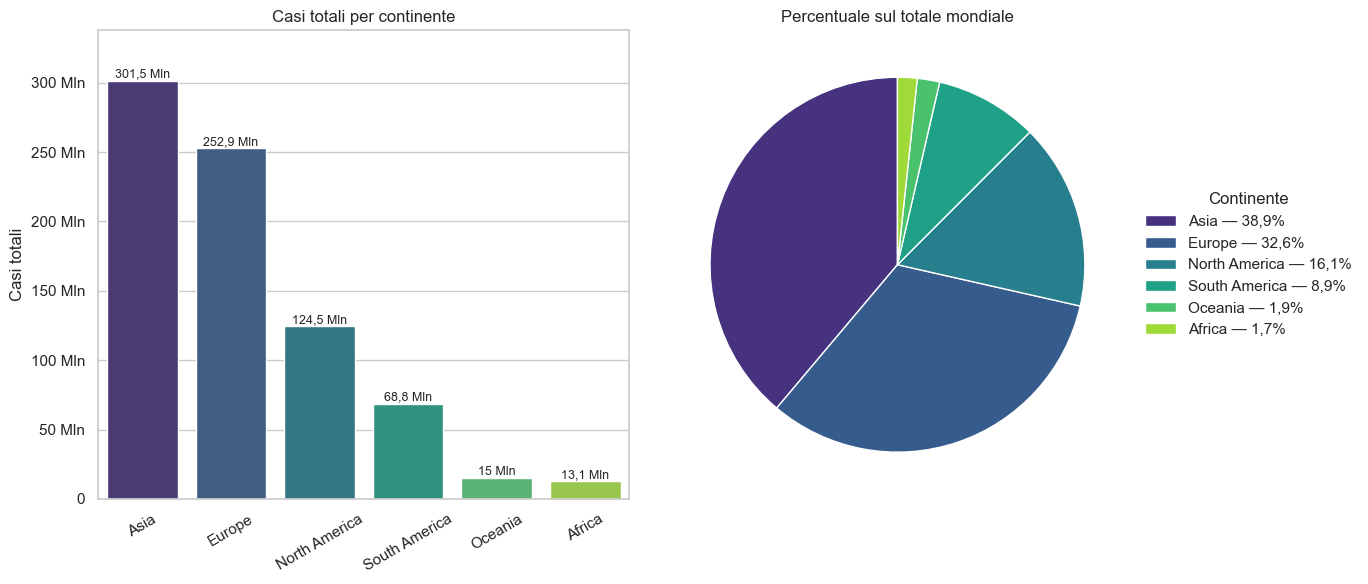

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=report_continenti, x='continente', y='casi_totali', hue='continente',
            palette='viridis', legend=False, ax=axes[0])
axes[0].set_title("Casi totali per continente")
axes[0].set_ylabel("Casi totali")
axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=30)
axes[0].yaxis.set_major_formatter(FMT_GRANDEZZE)   # niente 1e8: etichette in 'Mln'
axes[0].margins(y=0.12)                             # spazio per le etichette sopra le barre
for barra in axes[0].patches:
    h = barra.get_height()
    if h and h == h:
        axes[0].text(barra.get_x() + barra.get_width() / 2, h, _fmt_grandezze(h),
                     ha='center', va='bottom', fontsize=9)

# Torta con legenda esterna: mettere le etichette sulle fette causa sovrapposizioni
# quando le quote sono piccole e vicine (Africa, Oceania) e taglia i nomi piu' lunghi
# (North America). Spostiamo continenti e percentuali in una legenda laterale.
colori = sns.color_palette('viridis', len(report_continenti))
wedges, _ = axes[1].pie(report_continenti['percentuale_sul_mondo'], startangle=90,
                        colors=colori, wedgeprops=dict(edgecolor='white'))
axes[1].set_title("Percentuale sul totale mondiale")
etichette_legenda = [
    f"{cont} — {perc:.1f}%".replace('.', ',')
    for cont, perc in zip(report_continenti['continente'], report_continenti['percentuale_sul_mondo'])
]
axes[1].legend(wedges, etichette_legenda, title="Continente",
               loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)

fig.tight_layout()
plt.show()

**Osservazione:** l'Asia ha il maggior numero di casi, seguita dall'Europa. Colpisce l'Africa, che pesa molto meno sul totale mondiale rispetto alla sua popolazione: il dato riflette soprattutto la minore capacità di testing in alcune aree, non necessariamente una minore diffusione reale del virus.

## 3. Analisi Italia 2022

### 3.1 Selezione e pulizia dei dati

In [12]:
italia_2022 = df[(df['location'] == 'Italy') & (df['date'].dt.year == 2022)].copy()
print(f"Righe totali Italia 2022 (tutti i giorni): {len(italia_2022)}")

# Nota: nel 2022 OWID riporta i nuovi casi per l'Italia con cadenza settimanale e
# riempie i giorni non-reporting con 0 (non con NaN). Per isolare le sole misurazioni
# reali filtriamo quindi 'new_cases' non nullo E diverso da zero.
italia_2022_misurato = italia_2022[italia_2022['new_cases'].notna() & (italia_2022['new_cases'] != 0)].copy()
print(f"Righe con una misurazione reale (settimanali): {len(italia_2022_misurato)}")

italia_2022_misurato[['date', 'new_cases', 'total_cases']].head(10)

Righe totali Italia 2022 (tutti i giorni): 365
Righe con una misurazione reale (settimanali): 52


,date,new_cases,total_cases
182927,2022-01-02,644604.0,6267035.0
182934,2022-01-09,1014262.0,7281297.0
182941,2022-01-16,1268153.0,8549450.0
182948,2022-01-23,1231741.0,9781191.0
182955,2022-01-30,1040184.0,10821375.0
182962,2022-02-06,721418.0,11542793.0
182969,2022-02-13,510537.0,12053330.0
182976,2022-02-20,374443.0,12427773.0
182983,2022-02-27,304907.0,12732680.0
182990,2022-03-06,257543.0,12990223.0


### 3.1bis Verifica della cadenza settimanale

Il filtro `new_cases != 0` assume che nel 2022 i nuovi casi per l'Italia siano riportati settimanalmente e che i giorni a zero siano semplici giorni non-reporting. Verifichiamolo sui dati (invece di limitarci ad assumerlo): se l'assunzione è corretta, gli intervalli tra due misurazioni successive devono essere tutti di 7 giorni. Questo controllo garantisce anche che il filtro non abbia scartato per errore un'eventuale settimana con 0 casi reali (che comparirebbe come un salto di 14 giorni).

In [13]:
date_misurate = italia_2022_misurato['date'].sort_values()
differenze_giorni = date_misurate.diff().dt.days.dropna()

print("Distribuzione della differenza (in giorni) tra una misurazione e la successiva:")
print(differenze_giorni.value_counts().sort_index())

quota_settimanale = (differenze_giorni == 7).mean() * 100
print(f"\nPercentuale di intervalli esattamente pari a 7 giorni: {quota_settimanale:.1f}%")

Distribuzione della differenza (in giorni) tra una misurazione e la successiva:
date
7.0    51
Name: count, dtype: int64

Percentuale di intervalli esattamente pari a 7 giorni: 100.0%


**Tutti** gli intervalli tra due misurazioni successive sono esattamente di 7 giorni (100%): questo conferma numericamente (non solo per assunzione) che nel 2022 i nuovi casi per l'Italia vengono riportati con cadenza settimanale, coerentemente con quanto indicato nel codebook per le colonne relative ai casi confermati. L'assenza di salti di 14 giorni conferma inoltre che il filtro `!= 0` non ha scartato alcuna settimana con misurazione reale.

### 3.2 a) Evoluzione dei casi totali dall'inizio alla fine dell'anno

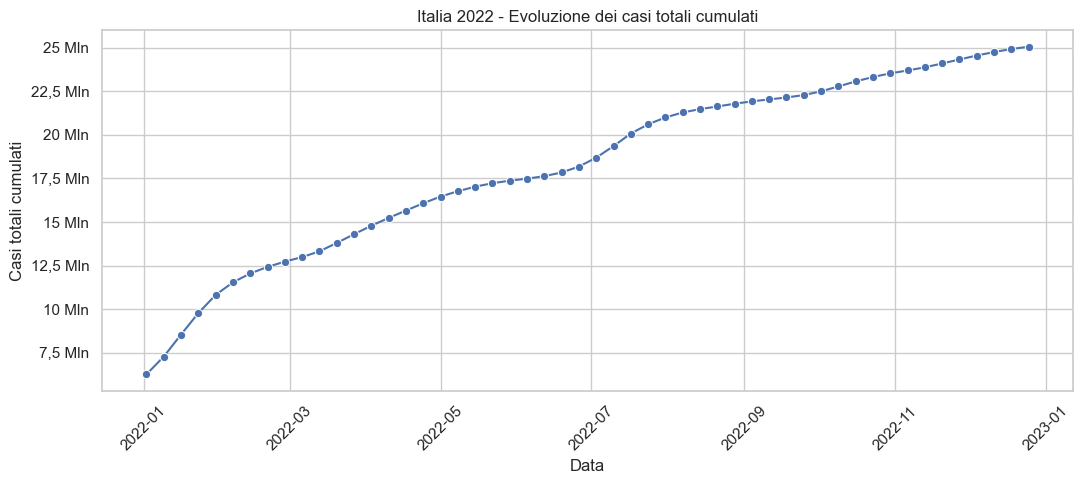

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=italia_2022_misurato, x='date', y='total_cases', marker='o', ax=ax)
ax.set_title("Italia 2022 - Evoluzione dei casi totali cumulati")
ax.set_xlabel("Data")
ax.set_ylabel("Casi totali cumulati")
ax.yaxis.set_major_formatter(FMT_GRANDEZZE)
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

### 3.2 b) Numero di nuovi casi rispetto alla data

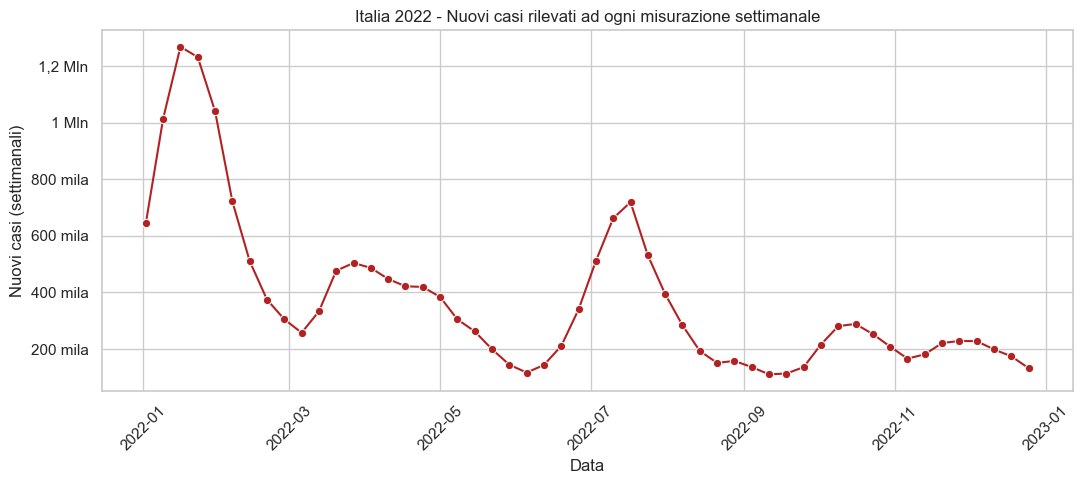

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=italia_2022_misurato, x='date', y='new_cases', marker='o', color='firebrick', ax=ax)
ax.set_title("Italia 2022 - Nuovi casi rilevati ad ogni misurazione settimanale")
ax.set_xlabel("Data")
ax.set_ylabel("Nuovi casi (settimanali)")
ax.yaxis.set_major_formatter(FMT_GRANDEZZE)
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

## 4. Confronto pazienti in terapia intensiva: Italia, Germania, Francia

Valori disponibili (non nulli) per Paese:
location
France     335
Germany    365
Italy      365
Name: icu_patients, dtype: int64


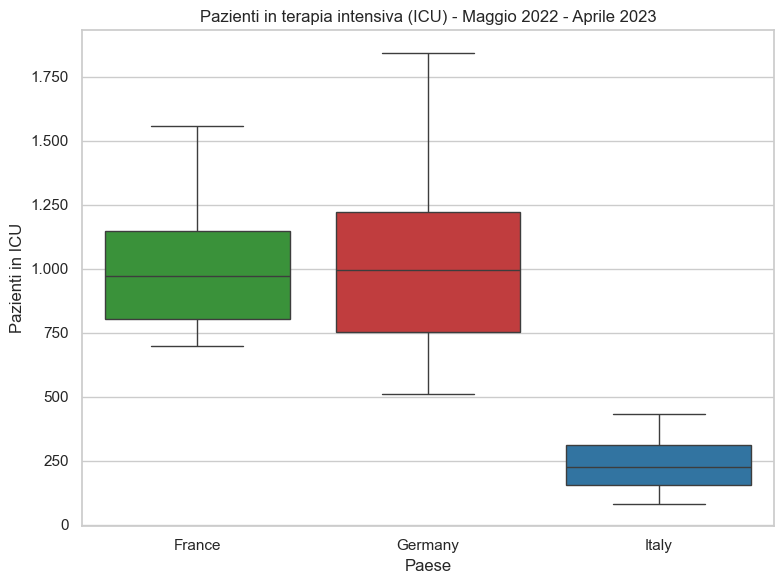

In [16]:
paesi_icu = ['Italy', 'Germany', 'France']
mask_periodo = (df['date'] >= '2022-05-01') & (df['date'] <= '2023-04-30')
icu_df = df[df['location'].isin(paesi_icu) & mask_periodo][['location', 'date', 'icu_patients']].copy()

print("Valori disponibili (non nulli) per Paese:")
print(icu_df.groupby('location')['icu_patients'].apply(lambda s: s.notna().sum()))

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=icu_df, x='location', y='icu_patients', hue='location',
            palette=PALETTE_NAZIONI, legend=False, ax=ax)
ax.set_title("Pazienti in terapia intensiva (ICU) - Maggio 2022 - Aprile 2023")
ax.set_xlabel("Paese")
ax.set_ylabel("Pazienti in ICU")
ax.yaxis.set_major_formatter(FMT_INTERI)
fig.tight_layout()
plt.show()

### 4.2 Statistiche numeriche e verifica di robustezza

Il boxplot da solo non quantifica il confronto: aggiungiamo una tabella di sintesi (mediana, quartili, deviazione standard) e verifichiamo che le conclusioni non cambino se si esclude il mese mancante alla Francia (aprile 2023).

In [17]:
# Tabella statistica di sintesi per il confronto ICU
statistiche_icu = icu_df.groupby('location')['icu_patients'].agg(
    Giorni_Validi='count',
    Mediana='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    Dev_Std='std',
    Minimo='min',
    Massimo='max',
).round(1)

statistiche_icu

,Giorni_Validi,Mediana,Q1,Q3,Dev_Std,Minimo,Massimo
location,,,,,,,
France,335,972.0,803.0,1145.5,220.2,699.0,1557.0
Germany,365,994.0,753.0,1221.0,306.1,512.0,1842.0
Italy,365,227.0,157.0,310.0,91.6,82.0,434.0


In [18]:
# Verifica di robustezza: la Francia ha giorni mancanti (aprile 2023).
# Ricalcoliamo le stesse statistiche sulla finestra comune in cui tutti
# e tre i Paesi hanno dati completi, per controllare che le conclusioni
# del boxplot non dipendano dal mese mancante alla Francia.
finestra_comune = df[
    (df['location'].isin(paesi_icu)) &
    (df['date'] >= '2022-05-01') & (df['date'] <= '2023-03-31')
].dropna(subset=['icu_patients'])

print("Statistiche sulla finestra comune (mag 2022 - mar 2023, tutti i Paesi presenti):")
finestra_comune.groupby('location')['icu_patients'].agg(
    Mediana='median', Q1=lambda x: x.quantile(0.25), Q3=lambda x: x.quantile(0.75)
).round(1)

Statistiche sulla finestra comune (mag 2022 - mar 2023, tutti i Paesi presenti):


,Mediana,Q1,Q3
location,,,
France,972.0,803.0,1145.5
Germany,1017.0,792.0,1240.0
Italy,233.0,180.0,316.5


In [19]:
# Contesto demografico: i valori sopra sono assoluti, non normalizzati per popolazione.
pop_icu = df[df['location'].isin(paesi_icu)].groupby('location')['population'].last()
print("Popolazione di riferimento (per contestualizzare i valori assoluti):")
for paese, p in pop_icu.items():
    print(f"  {paese}: {p:,.0f}")
print("\nNota: per un confronto normalizzato per la popolazione servirebbe la colonna",
      "'icu_patients_per_million', qui non usata perche' la traccia chiede i valori assoluti.")

Popolazione di riferimento (per contestualizzare i valori assoluti):
  France: 67,813,000
  Germany: 83,369,840
  Italy: 59,037,472

Nota: per un confronto normalizzato per la popolazione servirebbe la colonna 'icu_patients_per_million', qui non usata perche' la traccia chiede i valori assoluti.


### 4.1bis Localizzazione temporale dei dati mancanti in ICU

Sopra abbiamo contato quanti valori non nulli ci sono per Paese; ora individuiamo *quando* cadono i valori mancanti, per capire se sono concentrati in specifici sotto-periodi oppure sparsi lungo tutto l'intervallo.

In [20]:
def blocchi_mancanti(date_ordinate, flag_mancante):
    """Raggruppa le date mancanti in blocchi di giorni consecutivi."""
    date_mancanti = date_ordinate[flag_mancante].reset_index(drop=True)
    if date_mancanti.empty:
        return []
    nuovo_blocco = (date_mancanti.diff().dt.days != 1)
    gruppi = nuovo_blocco.cumsum()
    blocchi = date_mancanti.groupby(gruppi).agg(['min', 'max', 'count'])
    return blocchi.to_dict('records')

for paese in paesi_icu:
    serie_paese = icu_df[icu_df['location'] == paese].sort_values('date').reset_index(drop=True)
    flag = serie_paese['icu_patients'].isna()
    print(f"{paese}: {flag.sum()} / {len(serie_paese)} giorni mancanti nel periodo Mag 2022 - Apr 2023")
    for blocco in blocchi_mancanti(serie_paese['date'], flag):
        print(f"   buco dal {blocco['min'].date()} al {blocco['max'].date()} ({blocco['count']} giorni consecutivi)")
    if flag.sum() == 0:
        print("   nessun buco.")
    print()

Italy: 0 / 365 giorni mancanti nel periodo Mag 2022 - Apr 2023
   nessun buco.

Germany: 0 / 365 giorni mancanti nel periodo Mag 2022 - Apr 2023
   nessun buco.

France: 30 / 365 giorni mancanti nel periodo Mag 2022 - Apr 2023
   buco dal 2023-04-01 al 2023-04-30 (30 giorni consecutivi)



Localizzare i buchi nel tempo (e non solo contarli) permette di distinguere un problema di reporting temporaneo e circoscritto (ad esempio un buco di pochi giorni a cavallo di una festività) da un cambio strutturale nella raccolta dati (ad esempio l'interruzione del reporting negli ultimi mesi dell'intervallo osservato): le due situazioni richiederebbero interpretazioni molto diverse del confronto fatto nel boxplot sopra.

**Commento:**
Guardando insieme il boxplot e la tabella delle statistiche, **Germania e Francia si collocano sullo stesso ordine di grandezza** (mediane intorno ai ~990 e ~970 pazienti in terapia intensiva), mentre l'**Italia risulta nettamente più bassa** (mediana intorno ai ~230). Il confronto va letto tenendo presente due elementi: la Francia ha alcuni giorni mancanti (aprile 2023), ma la verifica di robustezza sulla finestra comune mostra che questo **non altera** il quadro; inoltre i valori sono **assoluti**, non pesati per popolazione (IT ~59M, DE ~83M, FR ~68M), quindi parte del divario Italia–Germania riflette anche la diversa dimensione demografica.

## 5. Pazienti ospedalizzati nel 2021: Italia, Germania, Francia, Spagna

In [21]:
paesi_hosp = ['Italy', 'Germany', 'France', 'Spain']
hosp_2021 = df[(df['location'].isin(paesi_hosp)) & (df['date'].dt.year == 2021)][['location', 'date', 'hosp_patients']].copy()

# Controllo dei valori nulli per Paese
nulli_per_paese = hosp_2021.groupby('location')['hosp_patients'].apply(lambda s: s.isna().sum())
totale_giorni = hosp_2021.groupby('location')['hosp_patients'].size()
riepilogo_nulli = pd.DataFrame({'giorni_totali': totale_giorni, 'giorni_nulli': nulli_per_paese})
riepilogo_nulli['percentuale_nulli'] = (riepilogo_nulli['giorni_nulli'] / riepilogo_nulli['giorni_totali'] * 100).round(1)
riepilogo_nulli

,giorni_totali,giorni_nulli,percentuale_nulli
location,,,
France,365,0,0.0
Germany,365,365,100.0
Italy,365,0,0.0
Spain,365,0,0.0


Somma dei pazienti ospedalizzati nel 2021 (somma dei valori giornalieri):
location
France     6008717.0
Italy      4419950.0
Spain      2411706.0
Germany          NaN
Name: hosp_patients, dtype: float64


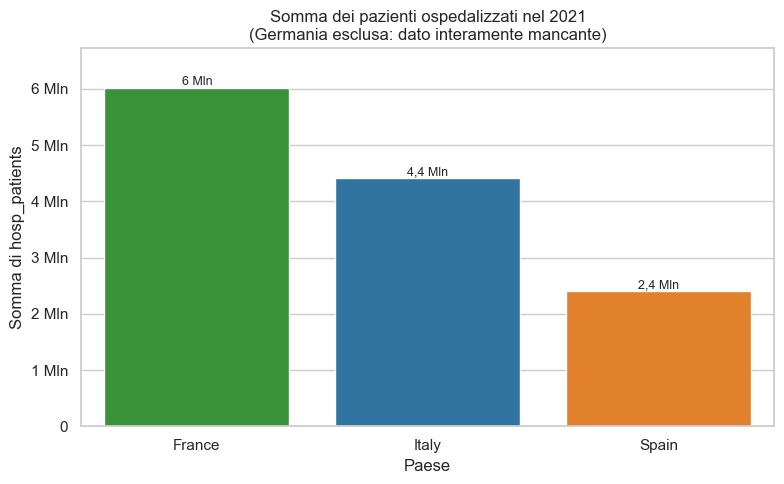

In [22]:
somma_hosp = hosp_2021.groupby('location')['hosp_patients'].sum(min_count=1).sort_values(ascending=False)
print("Somma dei pazienti ospedalizzati nel 2021 (somma dei valori giornalieri):")
print(somma_hosp)

# min_count=1 fa restituire NaN (e non 0) ai gruppi interamente nulli (es. Germania):
# la escludiamo esplicitamente dal grafico invece di mostrarla erroneamente a zero
somma_hosp_plot = somma_hosp.dropna()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=somma_hosp_plot.index, y=somma_hosp_plot.values, hue=somma_hosp_plot.index,
            palette=PALETTE_NAZIONI, legend=False, ax=ax)
ax.set_title("Somma dei pazienti ospedalizzati nel 2021\n(Germania esclusa: dato interamente mancante)")
ax.set_xlabel("Paese")
ax.set_ylabel("Somma di hosp_patients")
ax.yaxis.set_major_formatter(FMT_GRANDEZZE)
ax.margins(y=0.12)
for barra in ax.patches:
    h = barra.get_height()
    if h and h == h:
        ax.text(barra.get_x() + barra.get_width() / 2, h, _fmt_grandezze(h),
                ha='center', va='bottom', fontsize=9)
fig.tight_layout()
plt.show()

**Commento sui valori nulli:**
Come si vede dalla tabella sopra, la **Germania ha `hosp_patients` completamente nullo per tutto il 2021** (100% di valori mancanti), mentre Italia, Francia e Spagna hanno dati completi. In questo caso **non ha senso sostituire i valori mancanti** (ad esempio con la media o con zero): un'imputazione a zero farebbe pensare erroneamente che in Germania non ci fossero pazienti ospedalizzati, falsando qualunque confronto; un'imputazione con la media di altri Paesi sarebbe altrettanto arbitraria, perché i sistemi sanitari e le dinamiche epidemiche non sono comparabili 1:1. La scelta più corretta è **escludere esplicitamente la Germania** dal confronto sulla somma dei ricoveri 2021 (o segnalarla chiaramente come "dato non disponibile"), piuttosto che stimare un valore che potrebbe essere molto lontano dalla realtà.

## 6. Mini-extra: tasso di letalita' (Case-Fatality Ratio)

Come approfondimento personale, al di là delle richieste della traccia, calcolo il **Case-Fatality Ratio (CFR)** = `total_deaths / total_cases * 100` per le stesse quattro nazioni già analizzate nelle sezioni 4 e 5 (Italia, Germania, Francia, Spagna), per vedere se la letalità complessiva della malattia rispecchia la pressione ospedaliera osservata in precedenza.

In [23]:
paesi_cfr = ['Italy', 'Germany', 'France', 'Spain']

# Ultima rilevazione con total_cases e total_deaths non nulli, per ciascun Paese.
# groupby(...).tail(1) sostituisce il ciclo esplicito.
ultima_cfr = (
    df[df['location'].isin(paesi_cfr)]
      .dropna(subset=['total_cases', 'total_deaths'])
      .sort_values('date')
      .groupby('location')
      .tail(1)
      .copy()
)
ultima_cfr['cfr_percentuale'] = (ultima_cfr['total_deaths'] / ultima_cfr['total_cases'] * 100).round(2)
ultima_cfr['data_rilevazione'] = ultima_cfr['date'].dt.date

cfr_df = (
    ultima_cfr[['location', 'total_cases', 'total_deaths', 'cfr_percentuale', 'data_rilevazione']]
    .sort_values('cfr_percentuale', ascending=False)
    .reset_index(drop=True)
)
cfr_df

,location,total_cases,total_deaths,cfr_percentuale,data_rilevazione
0,Spain,13980340.0,121852.0,0.87,2024-08-04
1,Italy,26781078.0,197307.0,0.74,2024-08-04
2,Germany,38437756.0,174979.0,0.46,2024-08-04
3,France,38997490.0,168091.0,0.43,2024-08-04


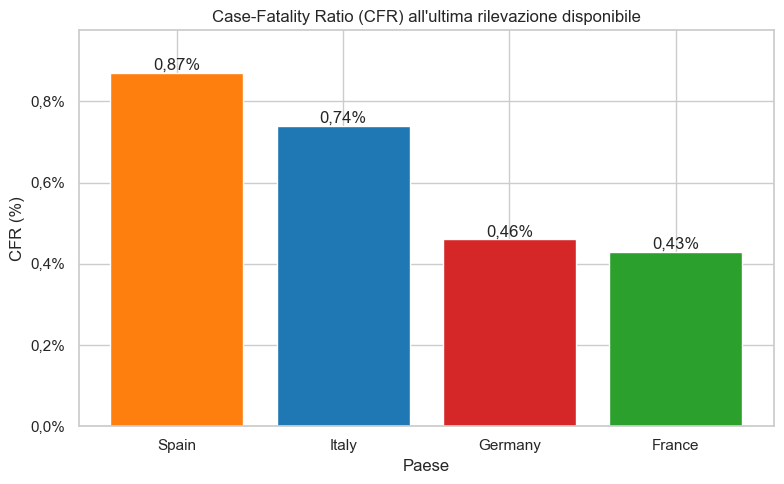

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
colori_barre = [PALETTE_NAZIONI[p] for p in cfr_df['location']]
ax.bar(cfr_df['location'], cfr_df['cfr_percentuale'], color=colori_barre)
ax.set_title("Case-Fatality Ratio (CFR) all'ultima rilevazione disponibile")
ax.set_xlabel("Paese")
ax.set_ylabel("CFR (%)")
ax.yaxis.set_major_formatter(FMT_PERCENTO)
ax.margins(y=0.12)
for i, v in enumerate(cfr_df['cfr_percentuale']):
    ax.text(i, v, f"{v:.2f}%".replace('.', ','), ha='center', va='bottom')
fig.tight_layout()
plt.show()

**Commento:** il CFR va letto con cautela, perché dipende fortemente dalla capacità di testing di ciascun Paese (chi testa meno individua una quota minore dei casi lievi, gonfiando artificialmente il CFR) e dalla struttura demografica della popolazione; per questo non va confuso con il tasso di letalità reale dell'infezione (Infection Fatality Rate), che richiederebbe stime sulla diffusione reale del virus e non solo sui casi confermati. Il confronto va quindi interpretato come un indicatore della letalità *osservata sui casi diagnosticati*, non della pericolosità assoluta della malattia in ciascun Paese.

## 7. Conclusioni

- Il dataset OWID copre ~250 tra Paesi e aggregati, con una netta distinzione tra righe-Paese (colonna `continent` valorizzata) e righe-aggregato (continenti, gruppi di reddito, `World`), distinzione fondamentale per non sommare due volte gli stessi dati.
- Il controllo dei duplicati ha individuato alcune coppie `(location, date)` ripetute, confinate a pochi territori/aggregati e non ai Paesi analizzati; sono state comunque rimosse tenendo la riga più completa. La consultazione del codebook ufficiale (non solo di `df.info()`) ha chiarito fonte e significato delle colonne usate, spiegandone anche le differenze di copertura e cadenza.
- L'Asia e l'Europa sono i continenti con il maggior numero di casi cumulati, seguiti da Nord America; Oceania e Africa chiudono la classifica. La somma per continente coincide esattamente con il totale `World`.
- In Italia, nel 2022, i nuovi casi settimanali mostrano un andamento decrescente dopo il picco di inizio anno (ondata Omicron), coerente con l'andamento osservato a livello europeo; la cadenza settimanale non è stata solo assunta ma verificata numericamente sulle date (100% di intervalli a 7 giorni).
- Il confronto ICU (2022-2023) mostra che **Germania e Francia hanno una pressione in terapia intensiva sullo stesso ordine di grandezza** (mediane ~990 e ~970), **nettamente superiore a quella dell'Italia** (~230); la verifica di robustezza e la localizzazione temporale dei dati mancanti confermano che il mese mancante alla Francia non altera il quadro. I valori sono assoluti e non pesati per popolazione.
- Sui ricoveri 2021, la Germania presenta dati interamente mancanti per `hosp_patients`: la scelta più corretta è escluderla esplicitamente dal confronto, anziché imputare un valore che rischierebbe di falsare l'analisi.
- Come mini-extra, il confronto del Case-Fatality Ratio tra le stesse 4 nazioni mostra differenze che non rispecchiano necessariamente la pressione ospedaliera osservata nelle sezioni precedenti: letalità osservata e pressione sui sistemi sanitari sono fenomeni correlati, ma non equivalenti, e vanno letti alla luce delle differenze di testing tra Paesi.

**Limite generale dell'analisi:** il dataset OWID aggiorna la frequenza di rilevazione nel tempo (da giornaliera a settimanale in molte serie), per cui confronti tra periodi con granularità diversa vanno letti con cautela.